In [61]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
df = pd.read_csv("../data/cleaned.csv")

df.head()

,exercise,knee_angle,elbow_angle,hip_angle,body_angle,symmetry_score,landmark_visibility,form_label
0,plank,92.274076,90.204844,177.277440,173.443771,0.980495,0.883269,plank_correct
1,plank,92.274076,90.204844,148.181538,155.808066,0.982693,0.884278,plank_hips_high
2,pushup,92.274076,83.034317,152.304493,145.856732,0.993650,0.869423,pushup_hips_high
3,pushup,92.274076,82.615740,174.706470,178.097925,0.996957,0.883972,pushup_correct
4,pushup,92.274076,68.553589,175.997185,179.385176,0.960992,0.958429,pushup_correct


In [63]:
print("Dataset shape:", df.shape)

Dataset shape: (912, 8)


In [64]:
X = df.drop(columns=["form_label"])
y = df["form_label"] 



print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)


Features:
['exercise', 'knee_angle', 'elbow_angle', 'hip_angle', 'body_angle', 'symmetry_score', 'landmark_visibility']

Target:
form_label


In [65]:
X = pd.get_dummies(
    X,
    columns=["exercise"],
    dtype=int
)

In [66]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y) 

for number, label in enumerate(label_encoder.classes_):
    print(number, "=", label)

0 = correct
1 = forward_lean
2 = knees_caving
3 = plank_correct
4 = plank_hips_high
5 = plank_hips_low
6 = pushup_body_sag
7 = pushup_correct
8 = pushup_elbow_flare
9 = pushup_hips_high
10 = shallow


In [67]:
print("X shape:", X.shape)
print("y shape:", y_encoded.shape)

X shape: (912, 9)
y shape: (912,)


In [68]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [69]:
print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

Training class distribution:
0     54
1     53
2     54
3     70
4     70
5     73
6     54
7     52
8     52
9     53
10    53
Name: count, dtype: int64


In [70]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [71]:
y_val_pred = model.predict(X_val)

val_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

print("Validation Accuracy:", val_accuracy * 100, "%")

Validation Accuracy: 85.40145985401459 %


In [72]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                    precision    recall  f1-score   support

           correct       0.85      0.92      0.88        12
      forward_lean       0.91      0.91      0.91        11
      knees_caving       1.00      1.00      1.00        12
     plank_correct       1.00      1.00      1.00        15
   plank_hips_high       0.88      0.93      0.90        15
    plank_hips_low       0.93      0.87      0.90        15
   pushup_body_sag       0.42      0.45      0.43        11
    pushup_correct       0.92      1.00      0.96        11
pushup_elbow_flare       1.00      0.92      0.96        12
  pushup_hips_high       0.40      0.36      0.38        11
           shallow       1.00      0.92      0.96        12

          accuracy                           0.85       137
         macro avg       0.84      0.84      0.84       137
      weighted avg       0.86      0.85      0.85       137



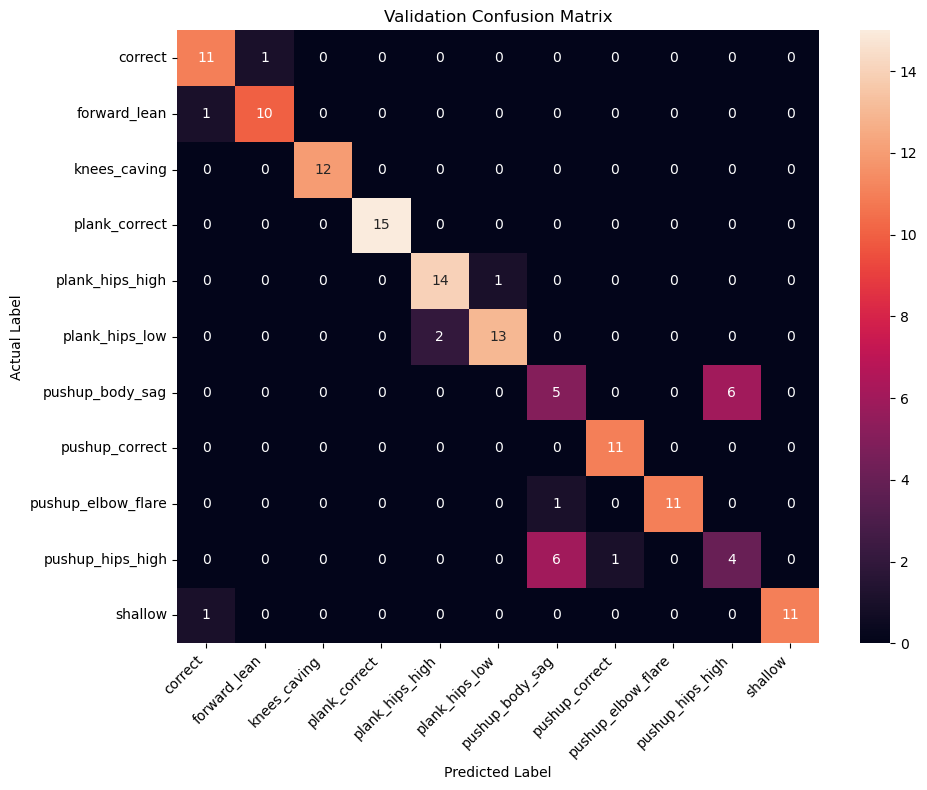

In [73]:
cm = confusion_matrix(
    y_val,
    y_val_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Validation Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [74]:
y_test_pred = model.predict(X_test)

In [75]:
test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

print("Test Accuracy:", test_accuracy * 100, "%")

Test Accuracy: 84.67153284671532 %


In [76]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                    precision    recall  f1-score   support

           correct       0.79      1.00      0.88        11
      forward_lean       1.00      0.91      0.95        11
      knees_caving       1.00      0.82      0.90        11
     plank_correct       1.00      1.00      1.00        15
   plank_hips_high       0.83      0.67      0.74        15
    plank_hips_low       0.74      0.88      0.80        16
   pushup_body_sag       0.58      0.58      0.58        12
    pushup_correct       0.92      1.00      0.96        12
pushup_elbow_flare       1.00      0.91      0.95        11
  pushup_hips_high       0.58      0.58      0.58        12
           shallow       1.00      1.00      1.00        11

          accuracy                           0.85       137
         macro avg       0.86      0.85      0.85       137
      weighted avg       0.85      0.85      0.85       137



In [77]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

               Feature  Importance
2            hip_angle    0.231930
3           body_angle    0.202499
4       symmetry_score    0.170381
1          elbow_angle    0.095484
6       exercise_plank    0.077973
0           knee_angle    0.062167
7      exercise_pushup    0.059053
5  landmark_visibility    0.054574
8       exercise_squat    0.045938


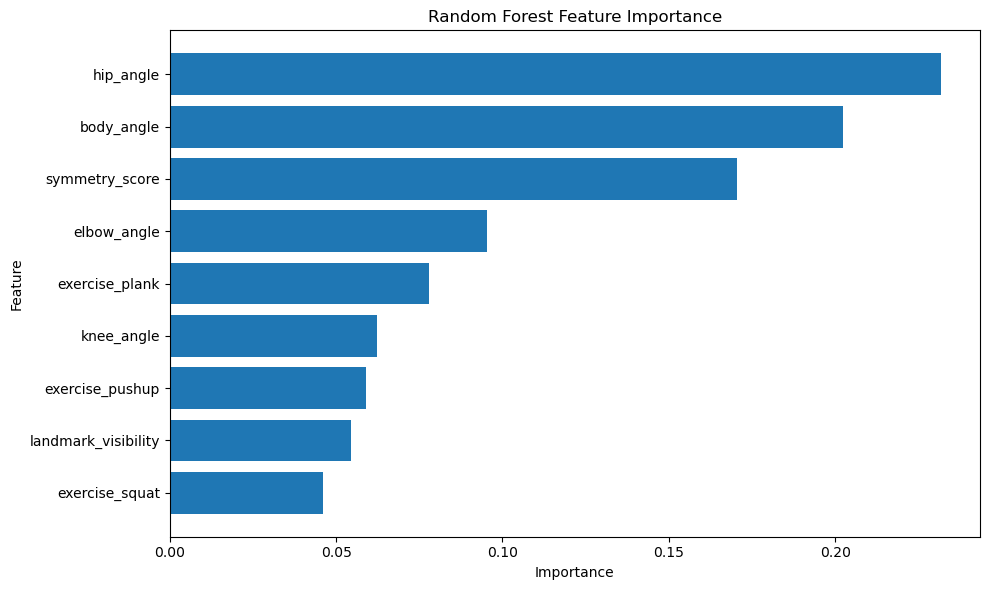

In [78]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [79]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

In [80]:
rf = RandomForestClassifier(
    random_state=42
)

In [81]:
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [82]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [83]:
print(
    "Best Cross-Validation Accuracy:",
    grid_search.best_score_ * 100,
    "%"
)

Best Cross-Validation Accuracy: 85.10826771653542 %


In [84]:
tuned_model = grid_search.best_estimator_

In [85]:
y_val_pred_tuned = tuned_model.predict(X_val)

tuned_val_accuracy = accuracy_score(
    y_val,
    y_val_pred_tuned
)

print(
    "Tuned Validation Accuracy:",
    tuned_val_accuracy * 100,
    "%"
)

Tuned Validation Accuracy: 85.40145985401459 %


In [86]:
print("Original Validation Accuracy:",
      val_accuracy * 100, "%")

print("Tuned Validation Accuracy:",
      tuned_val_accuracy * 100, "%")

Original Validation Accuracy: 85.40145985401459 %
Tuned Validation Accuracy: 85.40145985401459 %


In [87]:
y_test_pred_tuned = tuned_model.predict(X_test)

tuned_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_tuned
)

print(
    "Final Tuned Test Accuracy:",
    tuned_test_accuracy * 100,
    "%"
)

Final Tuned Test Accuracy: 84.67153284671532 %


In [88]:
print(
    classification_report(
        y_test,
        y_test_pred_tuned,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                    precision    recall  f1-score   support

           correct       0.79      1.00      0.88        11
      forward_lean       1.00      0.91      0.95        11
      knees_caving       1.00      0.82      0.90        11
     plank_correct       1.00      1.00      1.00        15
   plank_hips_high       0.83      0.67      0.74        15
    plank_hips_low       0.74      0.88      0.80        16
   pushup_body_sag       0.58      0.58      0.58        12
    pushup_correct       0.92      1.00      0.96        12
pushup_elbow_flare       1.00      0.91      0.95        11
  pushup_hips_high       0.58      0.58      0.58        12
           shallow       1.00      1.00      1.00        11

          accuracy                           0.85       137
         macro avg       0.86      0.85      0.85       137
      weighted avg       0.85      0.85      0.85       137



In [90]:
import joblib

joblib.dump(
    tuned_model,
    "../model/sifra_form_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [92]:
joblib.dump(
    label_encoder,
    "../model/label_encoder.pkl"
)

print("Label encoder saved successfully!")

Label encoder saved successfully!


In [94]:
feature_columns = X.columns.tolist()

joblib.dump(
    feature_columns,
    "../model/feature_columns.pkl"
)

print("Feature columns saved successfully!")

Feature columns saved successfully!
